In [62]:
import sys
print(sys.executable)

c:\Users\Robert\image-degradation-nn\.venv\Scripts\python.exe


In [63]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu132
CUDA available: True
GPU: NVIDIA GeForce RTX 4080


In [64]:
import json
from pathlib import Path

with open("splits.json", "r") as f:
    splits = json.load(f)

print("Classes:", splits["num_classes"])
print("Training images:", len(splits["train"]))
print("Validation images:", len(splits["val"]))
print("Testing images:", len(splits["test"]))

Classes: 45
Training images: 22050
Validation images: 4725
Testing images: 4725


## Dataset Loading

Load the predefined training and validation partitions
using the group's shared dataset implementation.

In [65]:

from dataset import get_dataloader

BATCH_SIZE = 64

train_loader = get_dataloader(
    "splits.json",
    "NWPU-RESISC45",
    split="train",
    batch_size=BATCH_SIZE,
    num_workers=0
)

val_loader = get_dataloader(
    "splits.json",
    "NWPU-RESISC45",
    split="val",
    batch_size=BATCH_SIZE,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Training batches: 345
Validation batches: 74


Verify a batch of images

In [66]:
images, labels = next(iter(train_loader))

print("Image dimensions:", images.shape)
print("Label dimensions:", labels.shape)
print("Sample labels:", labels[:10])

Image dimensions: torch.Size([64, 3, 256, 256])
Label dimensions: torch.Size([64])
Sample labels: tensor([41,  0, 27, 34, 21,  1,  4, 24, 13, 19])


We have confirmed that the actual photos have been loaded, and not just their file paths.

In [67]:
import random
import numpy as np

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

## Model Architecture

Load an ImageNet-pretrained ResNet-18 and replace
its final classification layer with 45 outputs.
Unlike the frozen-backbone baseline, the pretrained
layers will be trainable during fine-tuning.

In [68]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Load pretrained ResNet-18
model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Replace the final classification layer
model.fc = nn.Linear(model.fc.in_features, 45)

# Enable full fine-tuning
for param in model.parameters():
    param.requires_grad = True

# Move the model to the GPU
model = model.to(device)

print("Device:", device)
print("Classification layer:", model.fc)

Device: cuda
Classification layer: Linear(in_features=512, out_features=45, bias=True)


This replaces the original ImageNet classifier with one designed for your group's dataset.

"model.fc = nn.Linear(model.fc.in_features, 45)"

## Training Configuration

We use stochastic gradient descent (SGD) with momentum
and cross-entropy loss. The learning rate decreases
every seven epochs using a StepLR scheduler.

The configuration follows our group's frozen-backbone
baseline to maintain consistency between experiments.

In [69]:

import torch.optim as optim

# Training hyperparameters
EPOCHS = 25
LEARNING_RATE = 0.001
MOMENTUM = 0.9

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.SGD(
    model.parameters(),
    lr=LEARNING_RATE,
    momentum=MOMENTUM
)

# Learning rate scheduler
scheduler = optim.lr_scheduler.StepLR(
    optimizer,
    step_size=7,
    gamma=0.1
)

print("Training configuration initialized.")


Training configuration initialized.


## Forward Pass Verification

Verify that the model accepts a batch of training
images and produces 45 classification scores per image.

In [70]:

images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

model.eval()

with torch.no_grad():
    outputs = model(images)
    loss = criterion(outputs, labels)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Initial loss:", loss.item())


Input shape: torch.Size([64, 3, 256, 256])
Output shape: torch.Size([64, 45])
Initial loss: 3.965764284133911


## Training and Validation

This function processes one epoch of training or validation.
During training, the model's weights are updated through
backpropagation and stochastic gradient descent. During
validation, performance is measured without updating weights.

In [71]:

def run_epoch(loader, training=False):

    # Set training or evaluation mode
    model.train(training)

    running_loss = 0.0
    running_corrects = 0
    total_samples = 0

    with torch.set_grad_enabled(training):

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            if training:
                optimizer.zero_grad()

            # Forward propagation
            outputs = model(images)

            # Calculate loss
            loss = criterion(outputs, labels)

            if training:
                # Backpropagation
                loss.backward()

                # Update weights
                optimizer.step()

            # Determine predicted classes
            predictions = outputs.argmax(dim=1)

            # Accumulate performance metrics
            running_loss += loss.item() * images.size(0)
            running_corrects += (predictions == labels).sum().item()
            total_samples += labels.size(0)

    epoch_loss = running_loss / total_samples
    epoch_accuracy = running_corrects / total_samples

    return epoch_loss, epoch_accuracy


## ResNet-18 Fine-Tuning

The model is trained for 25 epochs using the original-resolution
training images. Training and validation loss and accuracy are
recorded after each epoch.

The model with the highest validation accuracy is saved
for subsequent image degradation experiments.

In [72]:

import time
import json
from pathlib import Path

# Create checkpoint directory
Path("checkpoints").mkdir(exist_ok=True)

checkpoint_path = "checkpoints/best_finetuned.pth"

best_val_acc = -1.0

# Store training and validation results
history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

for epoch in range(EPOCHS):

    start_time = time.time()

    print(f"Starting epoch {epoch + 1}/{EPOCHS}", flush=True)

    # Train the model
    train_loss, train_acc = run_epoch(
        train_loader, training=True
    )

    # Validate the model
    val_loss, val_acc = run_epoch(
        val_loader, training=False
    )

    # Record performance
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    # Update learning rate
    scheduler.step()

    # Save the best performing model
    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "val_acc": val_acc,
            "val_loss": val_loss,
            "mode": "finetuned"
        }, checkpoint_path)

        print("Best model saved.")

    # Save training history
    with open("checkpoints/finetuning_history.json", "w") as f:
        json.dump(history, f, indent=4)

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%} | "
        f"Time: {elapsed:.1f}s",
        flush=True
    )

print(f"\nBest validation accuracy: {best_val_acc:.2%}")
print(f"Checkpoint saved to: {checkpoint_path}")


Starting epoch 1/25
Best model saved.
Epoch 01/25 | Train Loss: 1.7498 | Train Acc: 61.19% | Val Loss: 0.7323 | Val Acc: 82.18% | Time: 208.8s
Starting epoch 2/25
Best model saved.
Epoch 02/25 | Train Loss: 0.5790 | Train Acc: 85.72% | Val Loss: 0.4516 | Val Acc: 87.83% | Time: 46.0s
Starting epoch 3/25
Best model saved.
Epoch 03/25 | Train Loss: 0.3653 | Train Acc: 90.60% | Val Loss: 0.3529 | Val Acc: 90.03% | Time: 44.2s
Starting epoch 4/25
Best model saved.
Epoch 04/25 | Train Loss: 0.2633 | Train Acc: 93.13% | Val Loss: 0.3021 | Val Acc: 90.75% | Time: 45.8s
Starting epoch 5/25
Best model saved.
Epoch 05/25 | Train Loss: 0.1935 | Train Acc: 95.20% | Val Loss: 0.2728 | Val Acc: 91.68% | Time: 45.5s
Starting epoch 6/25
Best model saved.
Epoch 06/25 | Train Loss: 0.1496 | Train Acc: 96.53% | Val Loss: 0.2545 | Val Acc: 92.00% | Time: 44.6s
Starting epoch 7/25
Epoch 07/25 | Train Loss: 0.1138 | Train Acc: 97.63% | Val Loss: 0.2432 | Val Acc: 91.96% | Time: 44.2s
Starting epoch 8/25
Bes

## Training Results

Visualize training and validation accuracy and loss
across all 25 epochs to evaluate convergence and
potential overfitting.

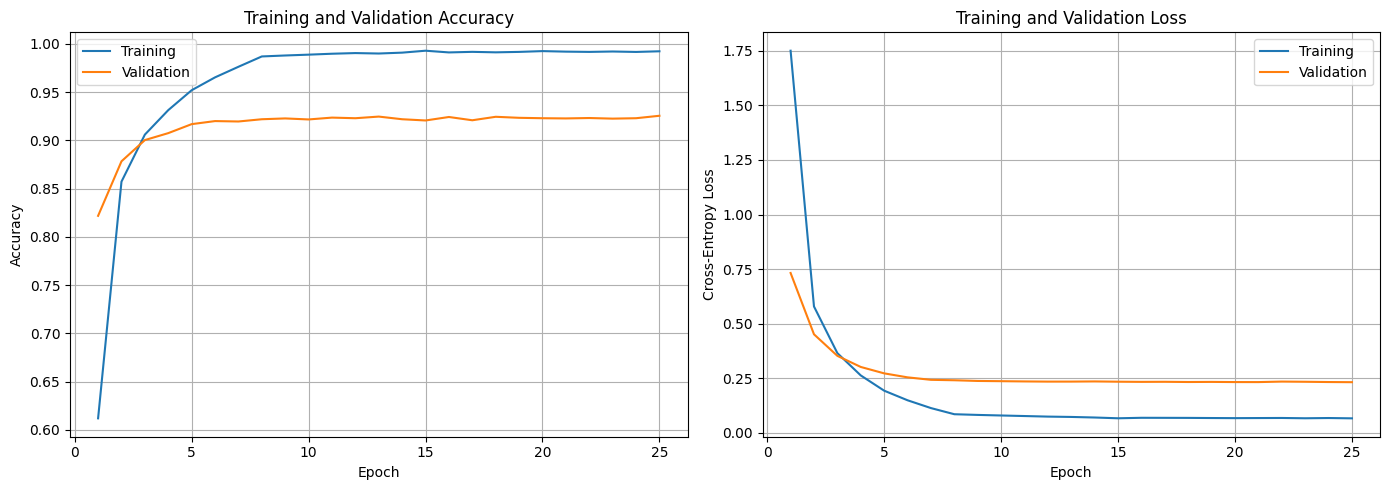

In [73]:

import matplotlib.pyplot as plt

epochs = range(1, len(history["train_acc"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
ax[0].plot(epochs, history["train_acc"], label="Training")
ax[0].plot(epochs, history["val_acc"], label="Validation")
ax[0].set_title("Training and Validation Accuracy")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Accuracy")
ax[0].legend()
ax[0].grid(True)

# Loss
ax[1].plot(epochs, history["train_loss"], label="Training")
ax[1].plot(epochs, history["val_loss"], label="Validation")
ax[1].set_title("Training and Validation Loss")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Cross-Entropy Loss")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.savefig("checkpoints/finetuning_results.png", dpi=300)
plt.show()


In [74]:

checkpoint = torch.load(
    "checkpoints/best_finetuned.pth",
    map_location="cpu",
    weights_only=True
)

print("Best epoch:", checkpoint["epoch"])
print("Validation accuracy:", f'{checkpoint["val_acc"]:.2%}')
print("Validation loss:", checkpoint["val_loss"])
print("Model mode:", checkpoint["mode"])


Best epoch: 25
Validation accuracy: 92.55%
Validation loss: 0.23232841710564953
Model mode: finetuned
